# Diabetes Progression Prediction
Regression project using the scikit-learn Diabetes dataset.

## Import Packages

In [3]:
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, cross_validate, KFold, GridSearchCV, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, BayesianRidge, HuberRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor, AdaBoostRegressor, BaggingRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis")
RANDOM_STATE = 42

## Load Dataset

In [4]:
data = load_diabetes(as_frame=True)
df = data.frame.copy()
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [5]:
print(df.shape)
df.info()

(442, 11)
<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


### Feature Description

In [6]:
print(data.DESCR[:1800])

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

## Exploratory Data Analysis

### Statistical Summary

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.268604e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


### Missing Values and Duplicates

In [8]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Duplicate rows: 0


### Target Distribution

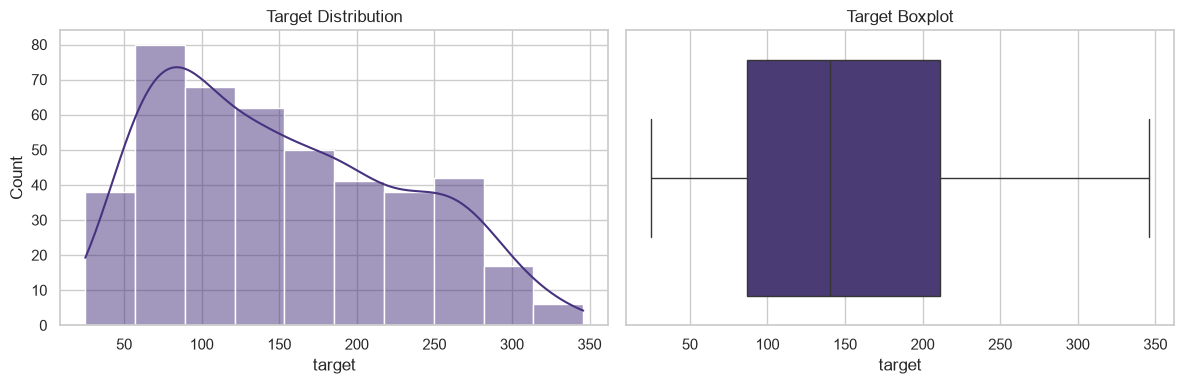

Skewness: 0.441


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["target"], kde=True, ax=ax[0])
ax[0].set_title("Target Distribution")
sns.boxplot(x=df["target"], ax=ax[1])
ax[1].set_title("Target Boxplot")
plt.tight_layout()
plt.show()
print("Skewness:", round(df["target"].skew(), 3))

### Feature Distributions

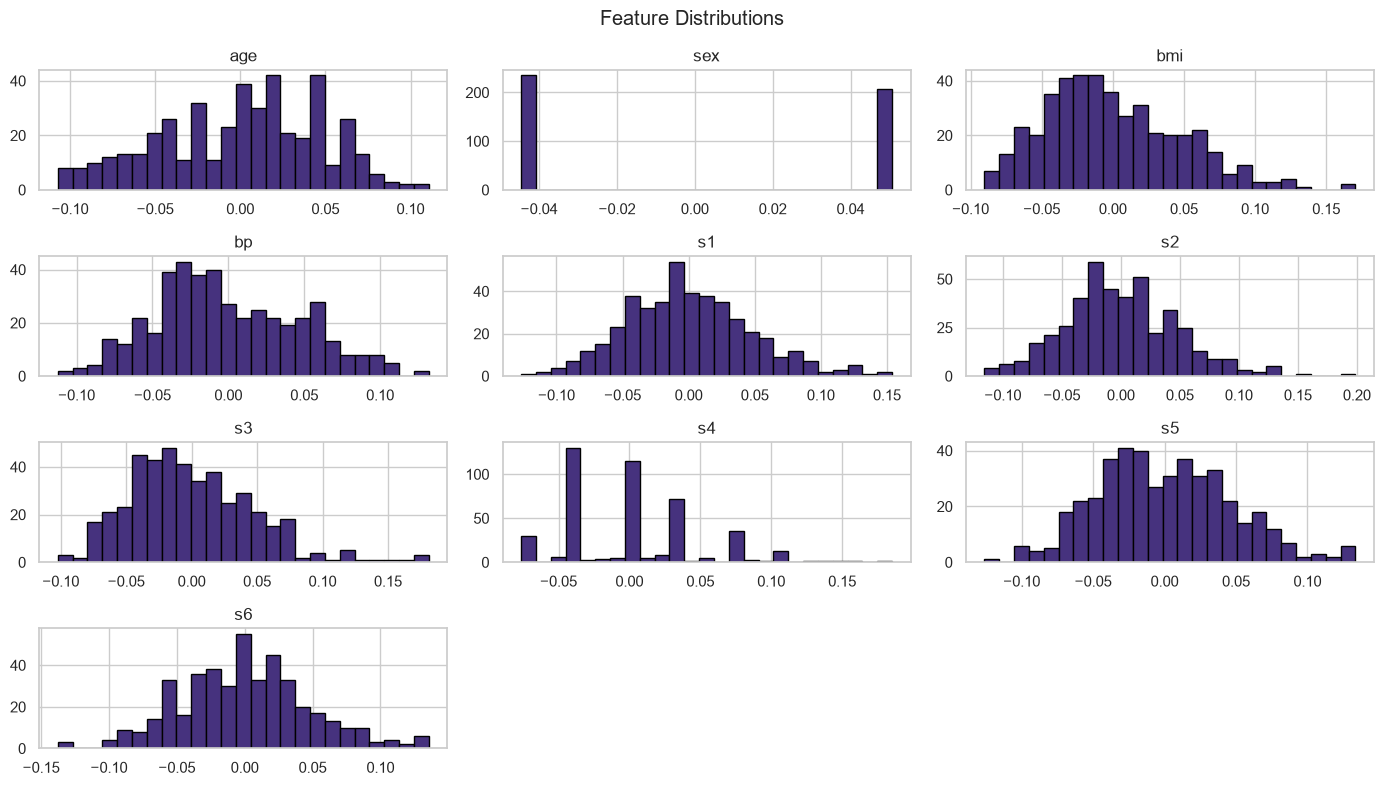

In [10]:
features = df.drop(columns="target").columns
df[features].hist(bins=25, figsize=(14, 8), edgecolor="black")
plt.suptitle("Feature Distributions")
plt.tight_layout()
plt.show()

### Outlier Check

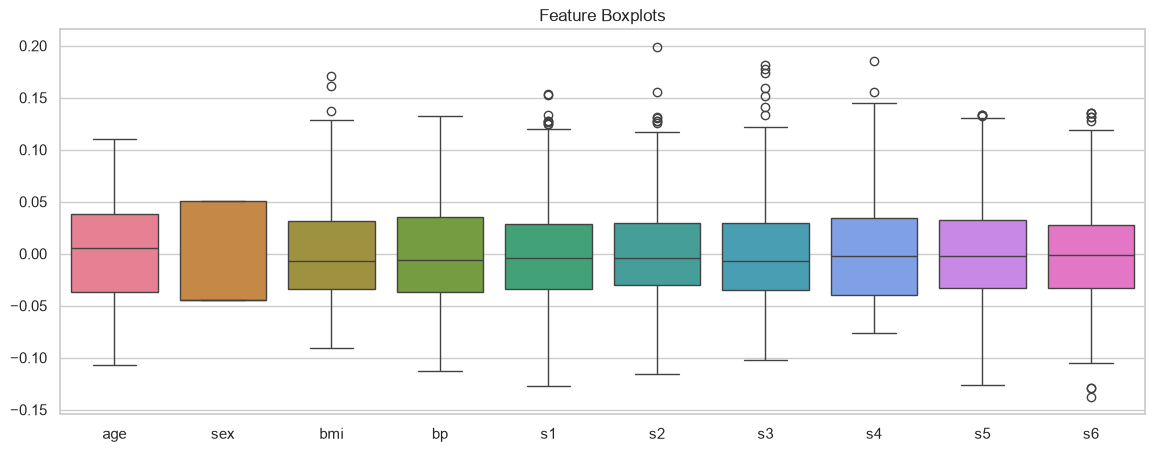

,outlier_count
age,0
sex,0
bmi,3
bp,0
s1,8
s2,7
s3,7
s4,2
s5,4
s6,9


In [11]:
plt.figure(figsize=(14, 5))
sns.boxplot(data=df[features])
plt.title("Feature Boxplots")
plt.show()

q1, q3 = df[features].quantile(0.25), df[features].quantile(0.75)
iqr = q3 - q1
outliers = ((df[features] < q1 - 1.5 * iqr) | (df[features] > q3 + 1.5 * iqr)).sum()
outliers.to_frame("outlier_count")

### Correlation Heatmap

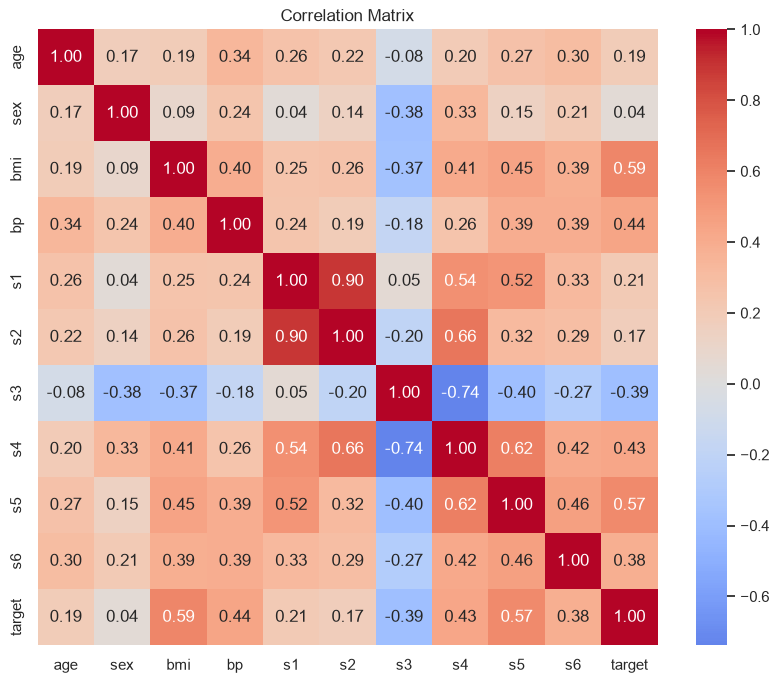

In [12]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.show()

### Correlation with Target

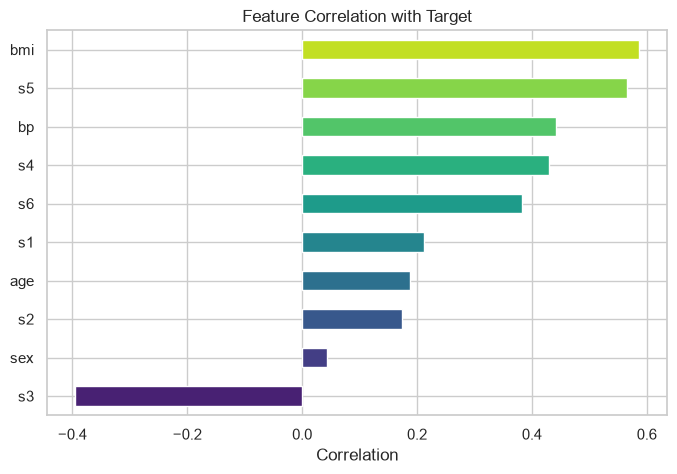

In [13]:
corr_target = df.corr()["target"].drop("target").sort_values()
plt.figure(figsize=(8, 5))
corr_target.plot(kind="barh", color=sns.color_palette("viridis", len(corr_target)))
plt.title("Feature Correlation with Target")
plt.xlabel("Correlation")
plt.show()

### Feature vs Target

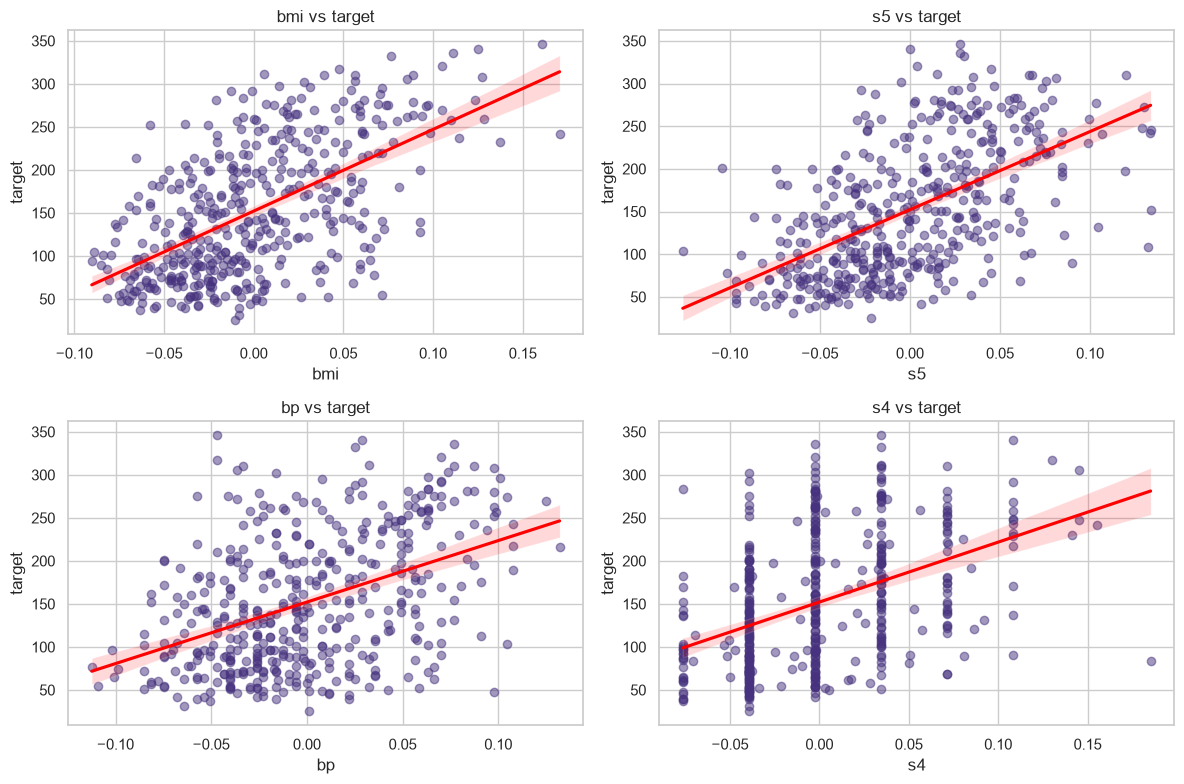

In [14]:
top = corr_target.abs().sort_values(ascending=False).index[:4]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), top):
    sns.regplot(x=df[col], y=df["target"], ax=ax, scatter_kws={"alpha": 0.5}, line_kws={"color": "red"})
    ax.set_title(f"{col} vs target")
plt.tight_layout()
plt.show()

### Pairplot of Top Features

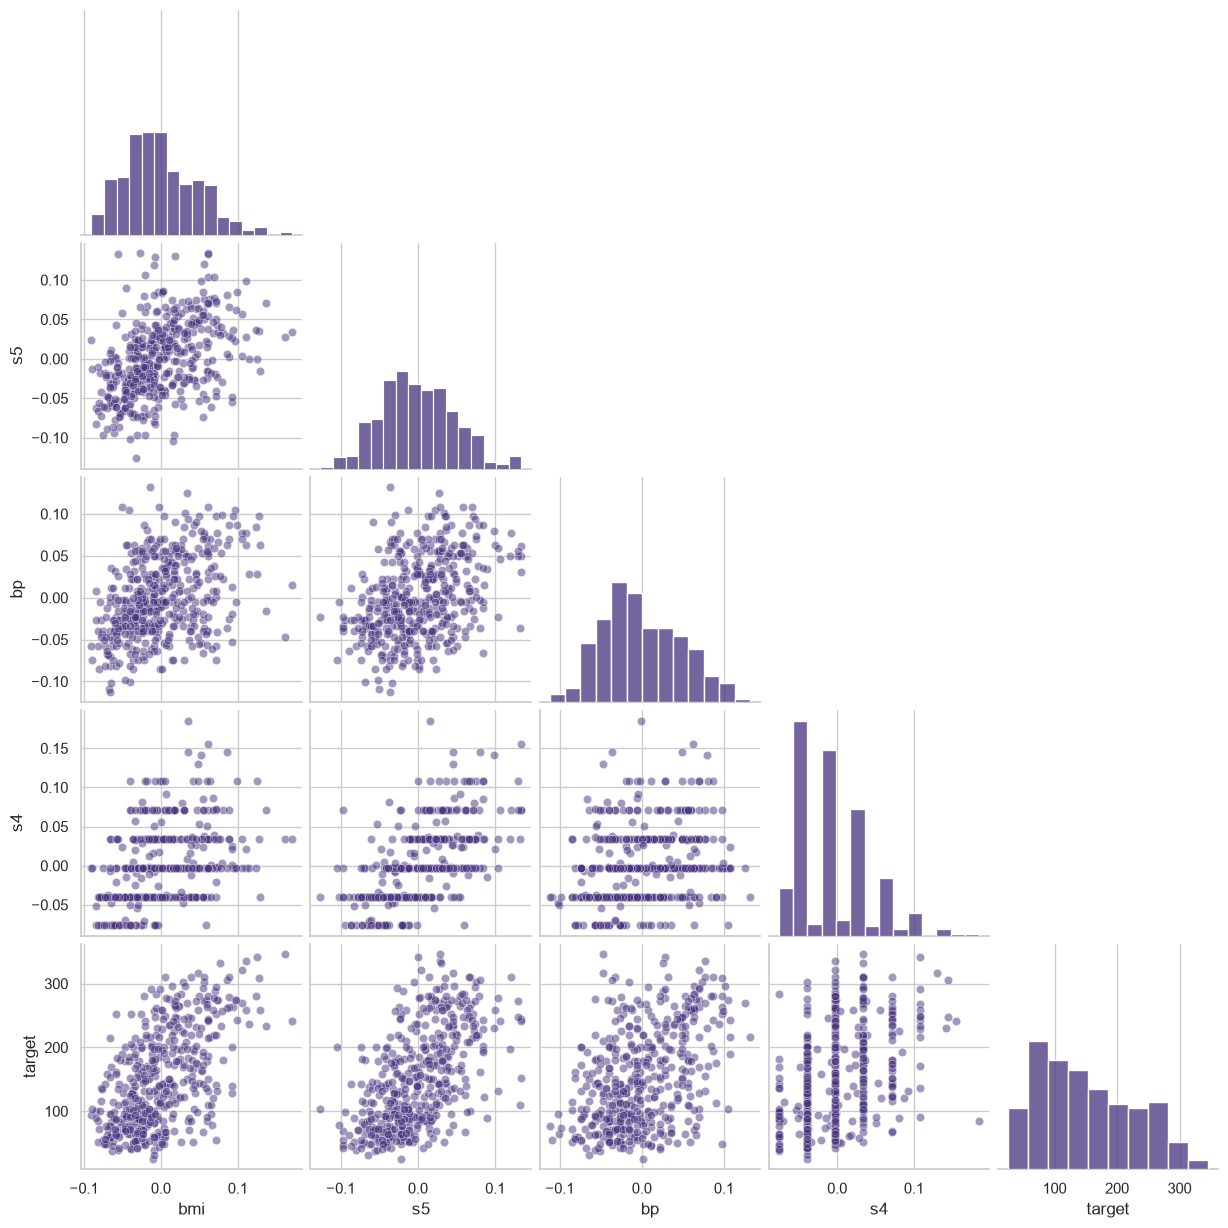

In [15]:
sns.pairplot(df[list(top) + ["target"]], corner=True, plot_kws={"alpha": 0.5})
plt.show()

### Multicollinearity (VIF)

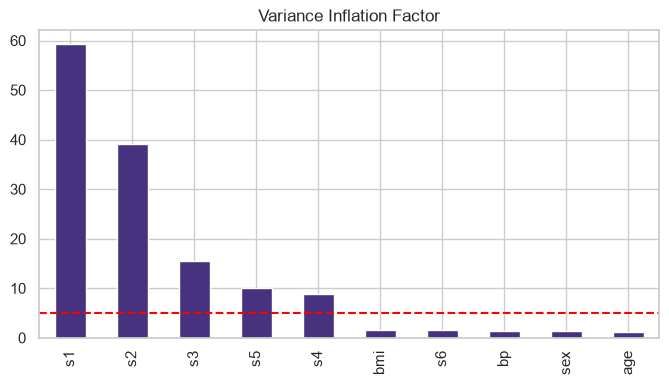

,VIF
s1,59.202510
s2,39.193370
s3,15.402156
s5,10.075967
s4,8.890986
bmi,1.509437
s6,1.484623
bp,1.459428
sex,1.278071
age,1.217307


In [16]:
corr_matrix = df[features].corr().values
vif = pd.Series(np.diag(np.linalg.inv(corr_matrix)), index=features, name="VIF").sort_values(ascending=False)
plt.figure(figsize=(8, 4))
vif.plot(kind="bar")
plt.axhline(5, color="red", linestyle="--")
plt.title("Variance Inflation Factor")
plt.show()
vif.to_frame()

## Preprocessing

### Remove Duplicates

In [17]:
df = df.drop_duplicates().reset_index(drop=True)
df.shape

(442, 11)

### Train-Test Split

In [18]:
X = df.drop(columns="target")
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (353, 10) Test: (89, 10)


### Scaling Check

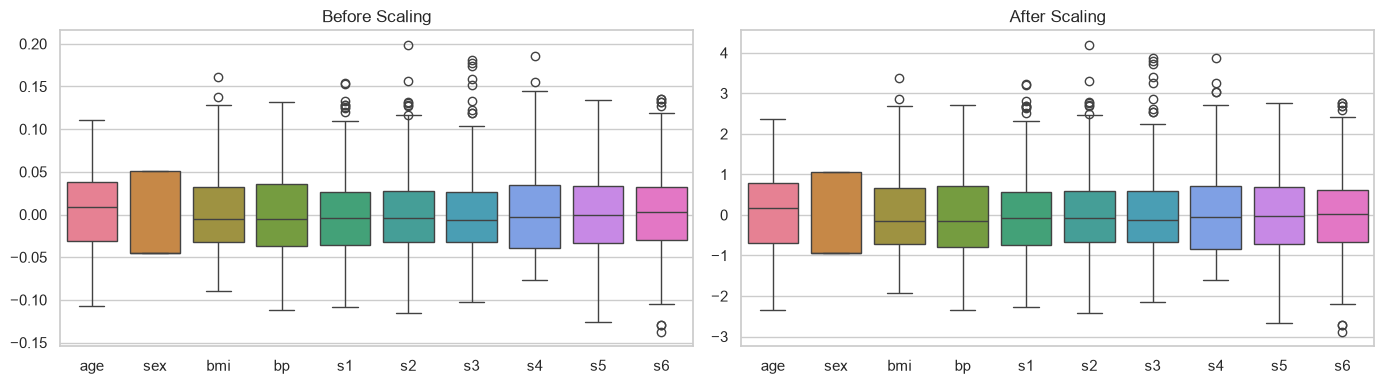

In [19]:
scaler = StandardScaler().fit(X_train)
X_train_scaled = pd.DataFrame(scaler.transform(X_train), columns=X.columns)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=X_train, ax=ax[0])
ax[0].set_title("Before Scaling")
sns.boxplot(data=X_train_scaled, ax=ax[1])
ax[1].set_title("After Scaling")
plt.tight_layout()
plt.show()

Scaling is applied inside each pipeline to avoid data leakage.

## Train All Models

In [20]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(random_state=RANDOM_STATE),
    "Lasso": Lasso(random_state=RANDOM_STATE),
    "ElasticNet": ElasticNet(random_state=RANDOM_STATE),
    "Bayesian Ridge": BayesianRidge(),
    "Huber": HuberRegressor(max_iter=1000),
    "KNN": KNeighborsRegressor(),
    "SVR": SVR(),
    "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(random_state=RANDOM_STATE),
    "Extra Trees": ExtraTreesRegressor(random_state=RANDOM_STATE),
    "Bagging": BaggingRegressor(random_state=RANDOM_STATE),
    "AdaBoost": AdaBoostRegressor(random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"r2": "r2", "rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"}

rows = []
fitted = {}
for name, model in models.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("model", model)])
    cv = cross_validate(pipe, X_train, y_train, cv=kf, scoring=scoring, n_jobs=-1)
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted[name] = pipe
    rows.append({
        "Model": name,
        "CV R2": cv["test_r2"].mean(),
        "CV R2 Std": cv["test_r2"].std(),
        "CV RMSE": -cv["test_rmse"].mean(),
        "CV MAE": -cv["test_mae"].mean(),
        "Test R2": r2_score(y_test, pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "Test MAE": mean_absolute_error(y_test, pred),
    })

results = pd.DataFrame(rows).sort_values("CV R2", ascending=False).reset_index(drop=True)
results.round(4)

,Model,CV R2,CV R2 Std,CV RMSE,CV MAE,Test R2,Test RMSE,Test MAE
0,Ridge,0.4808,0.0404,55.3742,44.9989,0.4541,53.7775,42.8120
1,Lasso,0.4808,0.0365,55.3885,45.1358,0.4669,53.1467,42.8030
2,Linear Regression,0.4804,0.0409,55.3946,45.0482,0.4526,53.8534,42.7941
3,Bayesian Ridge,0.4794,0.0378,55.4564,45.1015,0.4579,53.5905,42.8704
4,Huber,0.4730,0.0489,55.7427,45.2963,0.4468,54.1373,42.8797
5,ElasticNet,0.4584,0.0216,56.6585,46.8668,0.4548,53.7467,44.0718
6,Extra Trees,0.4290,0.0409,58.0833,47.2976,0.4685,53.0679,43.9224
7,Random Forest,0.3983,0.0719,59.4871,48.5263,0.4415,54.3984,44.1712
8,AdaBoost,0.3920,0.0469,59.9838,50.0531,0.4419,54.3774,45.0762
9,Gradient Boosting,0.3654,0.0585,61.1980,49.6144,0.4551,53.7307,44.5194


## Model Comparison

### R2 Score

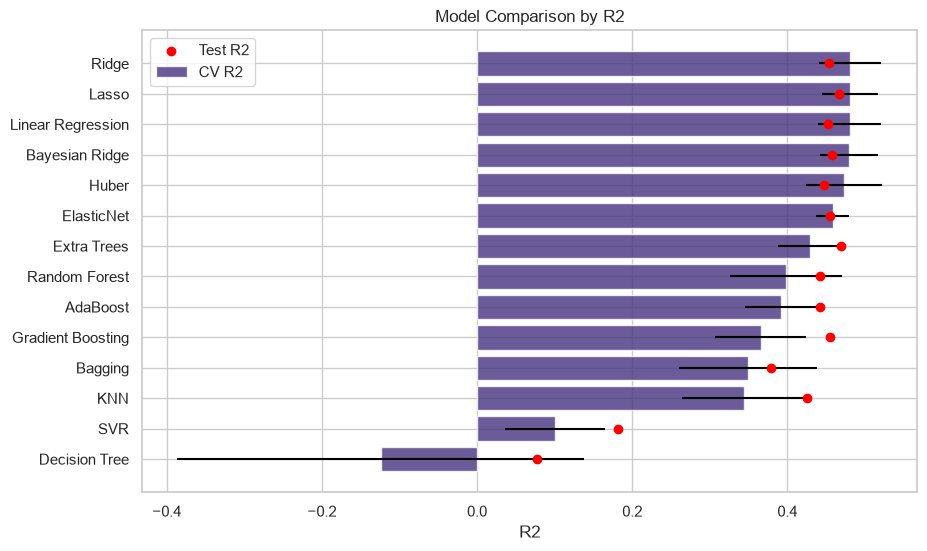

In [21]:
fig, ax = plt.subplots(figsize=(10, 6))
order = results.sort_values("CV R2")
ax.barh(order["Model"], order["CV R2"], xerr=order["CV R2 Std"], label="CV R2", alpha=0.8)
ax.scatter(order["Test R2"], order["Model"], color="red", zorder=3, label="Test R2")
ax.set_xlabel("R2")
ax.set_title("Model Comparison by R2")
ax.legend()
plt.show()

### Error Metrics

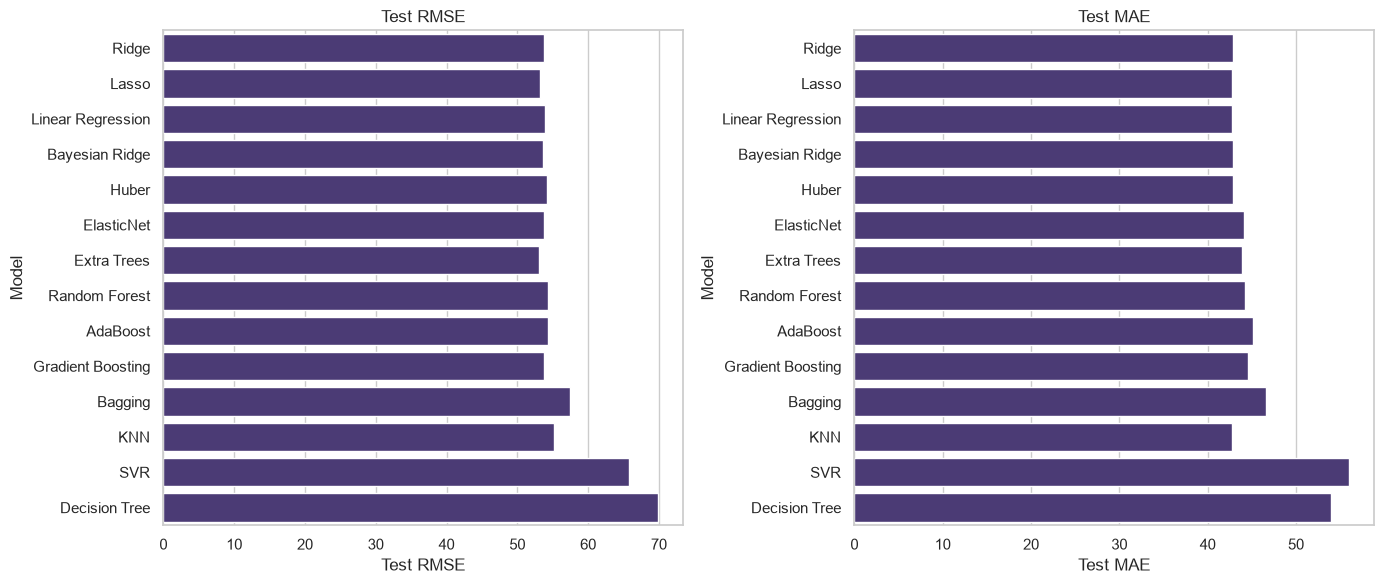

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(data=results, y="Model", x="Test RMSE", ax=ax[0])
ax[0].set_title("Test RMSE")
sns.barplot(data=results, y="Model", x="Test MAE", ax=ax[1])
ax[1].set_title("Test MAE")
plt.tight_layout()
plt.show()

### Best Model

In [23]:
best_name = results.loc[0, "Model"]
print("Best model:", best_name)
results.head(5).round(4)

Best model: Ridge


,Model,CV R2,CV R2 Std,CV RMSE,CV MAE,Test R2,Test RMSE,Test MAE
0,Ridge,0.4808,0.0404,55.3742,44.9989,0.4541,53.7775,42.8120
1,Lasso,0.4808,0.0365,55.3885,45.1358,0.4669,53.1467,42.8030
2,Linear Regression,0.4804,0.0409,55.3946,45.0482,0.4526,53.8534,42.7941
3,Bayesian Ridge,0.4794,0.0378,55.4564,45.1015,0.4579,53.5905,42.8704
4,Huber,0.4730,0.0489,55.7427,45.2963,0.4468,54.1373,42.8797


## Grid Search on Best Model

In [24]:
param_grids = {
    "Linear Regression": {"model__fit_intercept": [True, False]},
    "Ridge": {"model__alpha": [0.01, 0.1, 1, 10, 50, 100], "model__solver": ["auto", "svd", "cholesky", "lsqr"]},
    "Lasso": {"model__alpha": [0.001, 0.01, 0.1, 0.5, 1, 5]},
    "ElasticNet": {"model__alpha": [0.001, 0.01, 0.1, 1], "model__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]},
    "Bayesian Ridge": {"model__alpha_1": [1e-7, 1e-6, 1e-5], "model__alpha_2": [1e-7, 1e-6, 1e-5],
                       "model__lambda_1": [1e-7, 1e-6, 1e-5], "model__lambda_2": [1e-7, 1e-6, 1e-5]},
    "Huber": {"model__epsilon": [1.1, 1.35, 1.5, 2.0], "model__alpha": [1e-4, 1e-3, 1e-2, 1e-1]},
    "KNN": {"model__n_neighbors": [3, 5, 7, 9, 11, 15], "model__weights": ["uniform", "distance"], "model__p": [1, 2]},
    "SVR": {"model__C": [0.1, 1, 10, 100], "model__gamma": ["scale", 0.01, 0.1], "model__kernel": ["rbf", "linear"], "model__epsilon": [0.1, 1, 5]},
    "Decision Tree": {"model__max_depth": [3, 5, 7, 10, None], "model__min_samples_split": [2, 5, 10], "model__min_samples_leaf": [1, 3, 5]},
    "Random Forest": {"model__n_estimators": [100, 200, 300], "model__max_depth": [None, 5, 10], "model__min_samples_leaf": [1, 3, 5], "model__max_features": ["sqrt", 1.0]},
    "Extra Trees": {"model__n_estimators": [100, 200, 300], "model__max_depth": [None, 5, 10], "model__min_samples_leaf": [1, 3, 5]},
    "Bagging": {"model__n_estimators": [10, 50, 100], "model__max_samples": [0.5, 0.8, 1.0], "model__max_features": [0.5, 0.8, 1.0]},
    "AdaBoost": {"model__n_estimators": [50, 100, 200], "model__learning_rate": [0.01, 0.1, 0.5, 1.0], "model__loss": ["linear", "square"]},
    "Gradient Boosting": {"model__n_estimators": [100, 200, 300], "model__learning_rate": [0.01, 0.05, 0.1], "model__max_depth": [2, 3, 4], "model__subsample": [0.7, 1.0]},
}

base_pipe = Pipeline([("scaler", StandardScaler()), ("model", models[best_name])])
grid = GridSearchCV(base_pipe, param_grids[best_name], cv=kf, scoring="r2", n_jobs=-1, return_train_score=True)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV R2:", round(grid.best_score_, 4))

Best params: {'model__alpha': 1, 'model__solver': 'auto'}
Best CV R2: 0.4808


### Grid Search Results

In [25]:
cv_df = pd.DataFrame(grid.cv_results_).sort_values("rank_test_score")
cv_df[["params", "mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]].head(10)

,params,mean_train_score,mean_test_score,std_test_score,rank_test_score
9,"{'model__alpha': 1, 'model__solver': 'svd'}",0.530419,0.480784,0.040422,1
10,"{'model__alpha': 1, 'model__solver': 'cholesky'}",0.530419,0.480784,0.040422,1
8,"{'model__alpha': 1, 'model__solver': 'auto'}",0.530419,0.480784,0.040422,1
11,"{'model__alpha': 1, 'model__solver': 'lsqr'}",0.530419,0.480784,0.040422,4
6,"{'model__alpha': 0.1, 'model__solver': 'choles...",0.530836,0.480479,0.040801,5
4,"{'model__alpha': 0.1, 'model__solver': 'auto'}",0.530836,0.480479,0.040801,5
5,"{'model__alpha': 0.1, 'model__solver': 'svd'}",0.530836,0.480479,0.040801,7
7,"{'model__alpha': 0.1, 'model__solver': 'lsqr'}",0.530836,0.480479,0.040801,8
2,"{'model__alpha': 0.01, 'model__solver': 'chole...",0.530843,0.480377,0.040877,9
0,"{'model__alpha': 0.01, 'model__solver': 'auto'}",0.530843,0.480377,0.040877,9


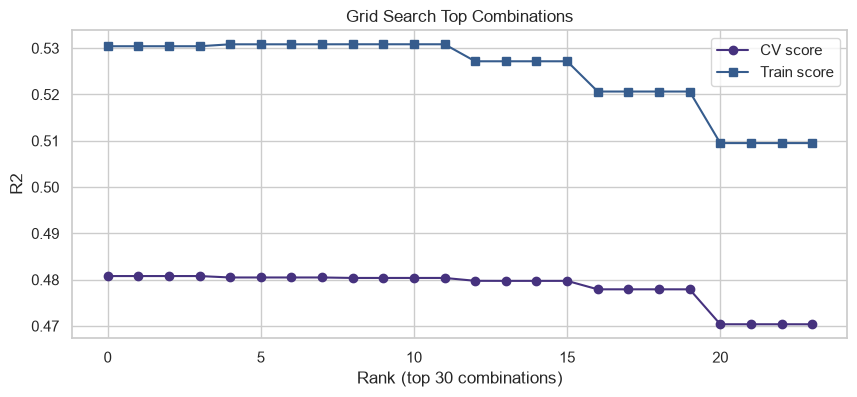

In [26]:
plt.figure(figsize=(10, 4))
plt.plot(cv_df["mean_test_score"].values[:30], marker="o", label="CV score")
plt.plot(cv_df["mean_train_score"].values[:30], marker="s", label="Train score")
plt.xlabel("Rank (top 30 combinations)")
plt.ylabel("R2")
plt.title("Grid Search Top Combinations")
plt.legend()
plt.show()

## Final Evaluation

In [27]:
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

tuned = {
    "R2": r2_score(y_test, y_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
    "MAE": mean_absolute_error(y_test, y_pred),
}
base_row = results[results["Model"] == best_name].iloc[0]
pd.DataFrame({
    "Before Tuning": [base_row["Test R2"], base_row["Test RMSE"], base_row["Test MAE"]],
    "After Tuning": [tuned["R2"], tuned["RMSE"], tuned["MAE"]],
}, index=["R2", "RMSE", "MAE"]).round(4)

,Before Tuning,After Tuning
R2,0.4541,0.4541
RMSE,53.7775,53.7775
MAE,42.8120,42.8120


### Actual vs Predicted

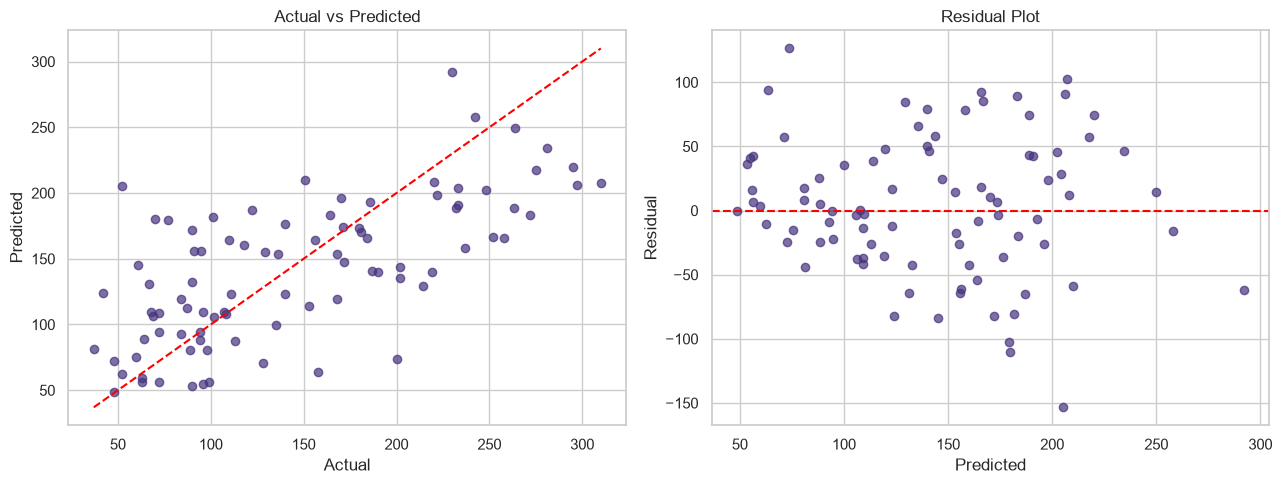

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_test, y_pred, alpha=0.7)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax[0].plot(lims, lims, "r--")
ax[0].set_xlabel("Actual")
ax[0].set_ylabel("Predicted")
ax[0].set_title("Actual vs Predicted")
residuals = y_test - y_pred
ax[1].scatter(y_pred, residuals, alpha=0.7)
ax[1].axhline(0, color="r", linestyle="--")
ax[1].set_xlabel("Predicted")
ax[1].set_ylabel("Residual")
ax[1].set_title("Residual Plot")
plt.tight_layout()
plt.show()

### Residual Distribution

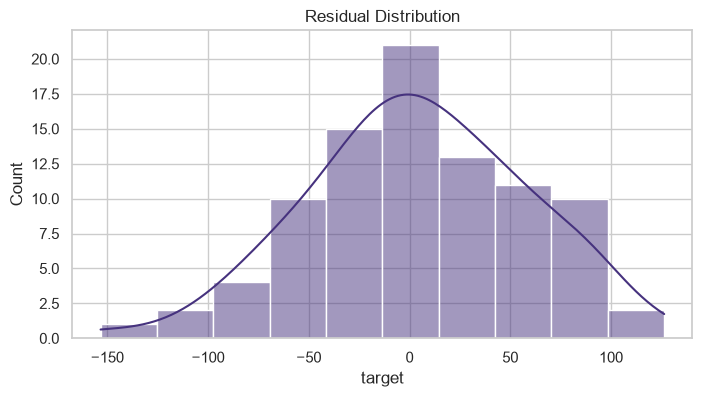

In [29]:
plt.figure(figsize=(8, 4))
sns.histplot(residuals, kde=True)
plt.title("Residual Distribution")
plt.show()

### Learning Curve

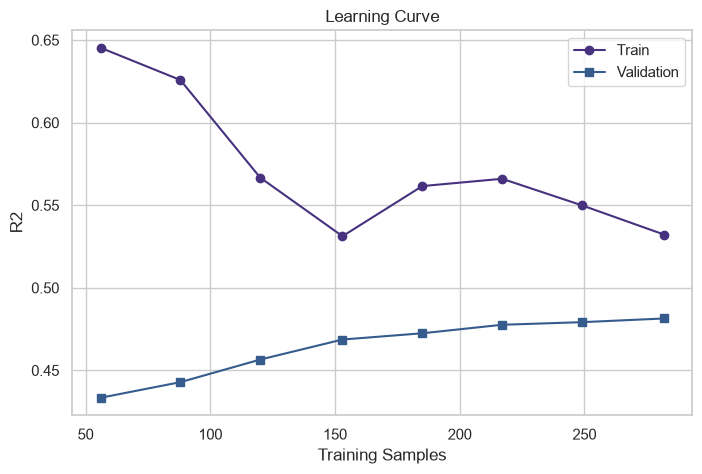

In [30]:
sizes, train_sc, val_sc = learning_curve(best_model, X_train, y_train, cv=kf, scoring="r2",
                                         train_sizes=np.linspace(0.2, 1.0, 8), n_jobs=-1)
plt.figure(figsize=(8, 5))
plt.plot(sizes, train_sc.mean(axis=1), marker="o", label="Train")
plt.plot(sizes, val_sc.mean(axis=1), marker="s", label="Validation")
plt.xlabel("Training Samples")
plt.ylabel("R2")
plt.title("Learning Curve")
plt.legend()
plt.show()

### Feature Importance

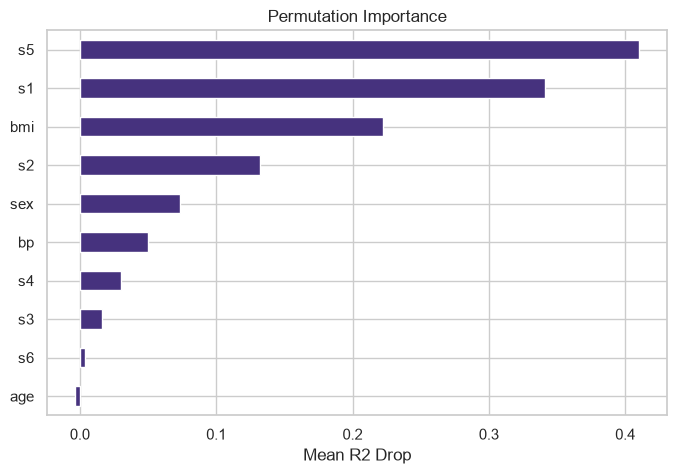

In [31]:


perm = permutation_importance(best_model, X_test, y_test, n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X.columns).sort_values()
plt.figure(figsize=(8, 5))
imp.plot(kind="barh")
plt.title("Permutation Importance")
plt.xlabel("Mean R2 Drop")
plt.show()

## Save Best Model

In [32]:
joblib.dump(best_model, "best_diabetes_model.joblib")
print("Saved: best_diabetes_model.joblib")

Saved: best_diabetes_model.joblib


### Verify Saved Model

In [33]:
loaded = joblib.load("best_diabetes_model.joblib")
print("Loaded R2:", round(r2_score(y_test, loaded.predict(X_test)), 4))
loaded.predict(X_test.iloc[:5])

Loaded R2: 0.4541


array([139.86277405, 179.9582406 , 135.71687469, 292.11578228,
       123.18931464])